# Covariate-adjusted perturbation effects on a genome-scale CD4+ T-cell screen

In a large screen, a target's cells and the control cells rarely come from the same donors, 10x lanes
or sequencing depths. If most of a target's cells sit in one lane, a plain comparison with the controls
reports that lane's differences as an effect of the knockdown.

`cx.tl.residual_effects` removes such differences with the method of Feng et al. (2025, *Cell
Genomics*):

1. normalise each cell to `log1p` counts per 10,000;
2. on the control cells only, fit each gene's expression to the covariates (for example donor and lane)
   by least squares;
3. take a target's effect as the average, over its cells, of observed minus fitted expression.

crispyx does this in one pass over the raw counts on disk, without loading the count matrix.

> **Key results**
>
> - With donor and lane as covariates, `residual_effects` agrees closely with the authors' own analysis
>   of the same cells: median per-target correlation 0.84, and 99.4% of their hits have the same sign.
> - Don't adjust for sequencing depth or mitochondrial share. Knockdowns change both, and adjusting for
>   them more than triples the hits with the opposite sign (0.6% to 1.9%).
> - On held-out donors, the two methods' calls replicate about equally often when each makes the same
>   number of calls. `residual_effects` calls twice as many hits, and most of the extra ones replicate.
> - From 540 GB of raw files to the last table, the notebook runs in 25 minutes on 32 cores.

**Data.** Resting CD4+ T cells from all four donors of the genome-scale CRISPRi Perturb-seq screen of
Zhu, Dann, Marson *et al.* (bioRxiv 2025): 7.4 million cells, 18,130 genes, 12,636 targeted genes. The
authors published their own estimates, made with DESeq2 on counts summed per donor and guide, for all
four donors together and for each pair of donors.

- **Part 1** compares `residual_effects` with the authors' estimates, for three choices of covariates.
- **Part 2** fits both methods on two donors and checks which one replicates on the other two.

Terms used throughout: a *target* is a knocked-down gene; *control cells* carry a non-targeting guide;
a *hit* is a gene whose Benjamini–Hochberg adjusted p-value for a target is below 0.1.

In [1]:
import os
import sys
import warnings
from contextlib import contextmanager
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Paths stay relative to this notebook's directory so that the paths crispyx
# echoes in its output are the same on every machine.
ROOT = Path('../..')
sys.path.insert(0, str(ROOT / 'src'))
# Progress bars off, so the saved notebook keeps only crispyx's summary lines.
os.environ.setdefault('TQDM_DISABLE', '1')
warnings.filterwarnings('ignore', message='IProgress not found')
import crispyx as cx

DATA_DIR = ROOT / 'data' / 'gwcd4i'
OUTPUT_DIR = Path('tutorial_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DONORS = ['D1', 'D2', 'D3', 'D4']

cores = len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity') else os.cpu_count()
print(f'crispyx {cx.__version__}, {cores} cores')

steps = []


@contextmanager
def measured(step):
    # record a step's wall time and this process's peak memory while it runs
    with cx.Profiler(timing=True, sampling=True, memory_method='rss', sample_interval=0.5) as profiler:
        yield
    stats = profiler.get_stats()
    minutes = stats['timing']['total_seconds'] / 60
    peak_gb = stats['memory']['peak_mb'] / 1024
    steps.append({'step': step, 'wall time (min)': round(minutes, 1), 'peak RSS (GB)': round(peak_gb, 1)})
    print(f'{step}: {minutes:.1f} min, peak RSS {peak_gb:.1f} GB')


@contextmanager
def warnings_as_messages():
    # print crispyx's warnings by message only: the default banner names the source file
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        warnings.simplefilter('ignore', DeprecationWarning)
        yield
    for message in dict.fromkeys(f'{w.category.__name__}: {w.message}' for w in caught):
        print(message)

crispyx 0.1.10, 32 cores


## Get the data

The files are public (MIT licence) in the S3 bucket `genome-scale-tcell-perturb-seq`; no account is
needed. Each donor's file holds every captured cell, 119–143 GB of raw counts (540 GB for the four).
Run once, from the repository root (this cell is not executed here):

```bash
mkdir -p data/gwcd4i && cd data/gwcd4i
BUCKET=https://genome-scale-tcell-perturb-seq.s3.amazonaws.com/marson2025_data
for donor in D1 D2 D3 D4; do curl -O "$BUCKET/${donor}_Rest.assigned_guide.h5ad"; done
curl -O "$BUCKET/GWCD4i.DE_stats.h5ad"             # the authors' results, 16.8 GB
curl -O "$BUCKET/GWCD4i.DE_stats.by_donors.h5mu"   # the same per pair of donors, 16.9 GB
```

# Part 1 — Comparison with the paper

## 1. Keep cells with one resolved guide

Each file also holds cells with no guide or several guides, and cells flagged as low quality.
`cx.write_filtered_subset` streams the cells to keep into a new file. The mask is built from `obs` alone
(`cx.load_obs`), without reading the counts.

In [2]:
filtered = {}
with measured('keep guide-resolved cells (4 files)'):
    for donor in DONORS:
        source = DATA_DIR / f'{donor}_Rest.assigned_guide.h5ad'
        obs = cx.load_obs(source)
        keep = (
            obs['guide_type'].eq('non-targeting')
            | (obs['guide_type'].eq('targeting') & obs['perturbed_gene_name'].notna())
        ) & ~obs['low_quality'].astype(bool)
        filtered[donor] = OUTPUT_DIR / f'{donor}.h5ad'
        with warnings_as_messages():
            cx.write_filtered_subset(
                source,
                cell_mask=keep.to_numpy(),
                gene_mask=np.ones(len(cx.load_var(source)), dtype=bool),
                output_path=filtered[donor],
            )
        print(f'{donor}: kept {keep.sum():,} of {len(obs):,} cells')

D1: kept 1,752,037 of 3,074,496 cells
D2: kept 1,983,457 of 2,940,194 cells
D3: kept 1,901,710 of 2,778,524 cells
D4: kept 1,749,091 of 2,693,903 cells
keep guide-resolved cells (4 files): 11.2 min, peak RSS 6.9 GB


## 2. Combine the donors

`cx.pp.concat_h5ad` streams the four files into one and records each cell's file in `obs['donor']`.
`shared_cells='error'` checks that no cell appears in two files.

> **Watch out:** the files do not list their genes in the same order (D3 and D4 differ from D1, as the
> first line of the output shows). `concat_h5ad` matches genes by name. Stacking the matrices as they
> are would silently give every cell of D3 and D4 the wrong gene names.

In [3]:
merged_path = OUTPUT_DIR / 'CD4T_Rest.h5ad'
gene_order = {donor: list(cx.load_var(filtered[donor]).index) for donor in DONORS}
print('same gene order as D1:', {donor: gene_order[donor] == gene_order['D1'] for donor in DONORS})
with measured('concatenate the donors'), warnings_as_messages():
    merged = cx.pp.concat_h5ad(
        [filtered[donor] for donor in DONORS],
        output_path=merged_path, label='donor', shared_cells='error',
    )
merged

same gene order as D1: {'D1': True, 'D2': True, 'D3': False, 'D4': False}
[cx] pp.concat_h5ad: Done  7386295 cells × 18130 genes
[cx] pp.concat_h5ad: Saving → tutorial_outputs/CD4T_Rest.h5ad
concatenate the donors: 6.8 min, peak RSS 8.9 GB


AnnData(path=tutorial_outputs/CD4T_Rest.h5ad, mode='r')

## 3. Labels and covariates

Each cell's label is its target, or `non-targeting` for control cells. It is passed as a `pd.Series`
indexed by cell, so nothing is written to the file. Cells labelled NaN are left out; part 2 uses this
to fit on some donors only.

`covariates` has no default. Adjust for how cells were processed: here donor and 10x lane, which no
knockdown changes. Sequencing depth (`log_total_counts`) and mitochondrial share (`mito_fraction`),
computed from the counts, are also available. But many knockdowns change them, so adjusting for them
removes part of the effect. Part 1 runs both designs to show the difference.

The table shows how the donors share 10x runs: D1 and D2 were sequenced in the first, D3 and D4 in the
second. Each lane belongs to one run, so the lanes already tell the runs apart, and one donor column is
redundant. `residual_effects` notes this ("rank 49 < 50 columns") and checks that every effect is still
unique.

In [4]:
obs = cx.load_obs(merged_path)
labels = (
    obs['perturbed_gene_name'].astype(object)
    .where(obs['guide_type'].ne('non-targeting'), 'non-targeting')
    .rename('perturbation')
)
print(f'{len(obs):,} cells, {labels.nunique() - 1:,} targeted genes, '
      f"{(labels == 'non-targeting').sum():,} control cells")
pd.crosstab(obs['lane_id'].str[:7].rename('10x run'), obs['donor'])

7,386,295 cells, 12,636 targeted genes, 313,989 control cells


donor,D1,D2,D3,D4
10x run,,,,
CD4i_R1,1752037,1983457,0,0
CD4i_R2,0,0,1901710,1749091


## 4. Effects for three designs

- **donor + lane**: the main design.
- **donor + lane + depth + mito**: the covariates Feng et al. used.
- **no covariates**: each target's mean minus the controls' mean.

`null` sets how each effect is turned into a z-score:

- `'robust'` (used here) estimates each gene's noise from how much its effect varies across targets.
  It assumes most targets leave a given gene unchanged, which holds in a genome-wide screen.
- `'model'` uses the control cells' scatter around the fit. It treats cells as independent, but cells
  that share a guide or a donor are not, so it calls too many hits.

Both noise estimates are saved, so either z-score can be computed later without another pass.

In [5]:
designs = {
    'donor + lane': ['donor', 'lane_id'],
    'donor + lane + depth + mito': ['donor', 'lane_id', 'log_total_counts', 'mito_fraction'],
    'no covariates': [],
}
results = {}
for name, covariates in designs.items():
    with measured(f'residual_effects, {name}'):
        results[name] = cx.tl.residual_effects(
            merged_path, labels, 'non-targeting',
            covariates=covariates, null='robust', gene_name_column='gene_name',
            output_path=OUTPUT_DIR / f"cd4t_{name.replace(' + ', '_').replace(' ', '_')}.h5ad",
        )
results['donor + lane']

[cx] residual_effects: Reading tutorial_outputs/CD4T_Rest.h5ad
[cx] residual_effects: 433 perturbation(s) have fewer than 10 cells and are left out: ['NOL10', 'JAK1', 'HGS', 'TRIM11', 'VIRMA', 'RPS8', 'SAMM50', 'DCTN5', 'TTC27', 'RPL13']
[cx] residual_effects: 12,203 perturbations, 313,989 control cells, design: 50 columns
[cx] residual_effects: the design has rank 49 < 50 columns (collinear covariates); every perturbation's design lies within the controls', so its effect is still unique.
[cx] residual_effects: estimated disk usage: 7.8 GB (1.5 TB free)
[cx] residual_effects: 12,203 perturbations x 18,130 genes (7,976 tested), robust null
[cx] residual_effects: Saving → tutorial_outputs/cd4t_donor_lane.h5ad
residual_effects, donor + lane: 1.6 min, peak RSS 18.5 GB
[cx] residual_effects: Reading tutorial_outputs/CD4T_Rest.h5ad
[cx] residual_effects: 433 perturbation(s) have fewer than 10 cells and are left out: ['NOL10', 'JAK1', 'HGS', 'TRIM11', 'VIRMA', 'RPS8', 'SAMM50', 'DCTN5', 'TTC2

AnnData(path=tutorial_outputs/cd4t_donor_lane.h5ad, mode='r')

The result is an on-disk `AnnData` with targets as rows and genes as columns:

| Where | What |
|---|---|
| `X` | the effect: a difference in mean `log1p(CP10k)` (natural log), **not** a log2 fold change |
| `layers` | `z_score`, `pvalue` and `pvalue_adj` (Benjamini–Hochberg within each target) |
| `obs` | cells per target and genes tested |
| `var` | control mean, both noise estimates, and `tested` (control mean above 0.1, as in Feng et al.) |

In [6]:
results['donor + lane'].backed.var.head()

,control_mean,residual_sd,robust_sd,tested
gene_name,,,,
TSPAN6,0.000071,0.007653,0.000587,False
TNMD,0.000002,0.001259,0.000044,False
DPM1,0.789105,0.611987,0.759587,True
SCYL3,0.264902,0.439038,0.455264,True
C1orf112,0.382648,0.552605,0.894379,True


In [7]:
def load_effects(result):
    # effect, z under both nulls, cells per perturbation and gene table of a result
    with h5py.File(result.path, 'r') as handle:
        effect = handle['X'][:]
        padj = handle['layers/pvalue_adj'][:]
    backed = result.backed
    var = backed.var
    n_cells = backed.obs['n_cells'].to_numpy()
    tested = var['tested'].to_numpy()
    out = {'targets': pd.Index(backed.obs_names), 'genes': pd.Index(backed.var_names),
           'effect': effect, 'padj': padj, 'n_cells': n_cells, 'var': var}
    for null, column in (('model', 'residual_sd'), ('robust', 'robust_sd')):
        spread = var[column].to_numpy()
        usable = tested & (spread > 0)
        z = np.full_like(effect, np.nan)
        z[:, usable] = effect[:, usable] * np.sqrt(n_cells)[:, None] / spread[usable]
        out[f'z_{null}'] = z
    return out


def column(group, key):
    # one obs/var column of an h5ad (or h5mu modality) group, decoding categoricals
    item = group[key]
    if isinstance(item, h5py.Group):
        return item['categories'][:].astype(str)[item['codes'][:]]
    values = item[:]
    return values.astype(str) if values.dtype.kind in 'SO' else values


def paper_table(path, modality=None, meta_columns=()):
    # resting-state rows of the authors' DESeq2 results (whole table, or one donor-pair modality)
    with h5py.File(path, 'r') as handle:
        group = handle if modality is None else handle['mod'][modality]
        names = column(group['obs'], 'target_contrast_gene_name')
        rows = np.flatnonzero(column(group['obs'], 'culture_condition') == 'Rest')
        rows = rows[~pd.Index(names[rows]).duplicated(keep=False)]
        # dense, uncompressed layers: one sequential read each, then the rows we need
        table = {name: group['layers'][name][:][rows] for name in ('zscore', 'log_fc', 'adj_p_value')}
        table['meta'] = pd.DataFrame({c: column(group['obs'], c)[rows] for c in meta_columns}, index=names[rows])
        table['targets'] = pd.Index(names[rows])
        table['genes'] = pd.Index(column(group['var'], 'gene_name'))
    return table


def on(source_targets, source_genes, matrix, targets, genes):
    # rows and columns of matrix for the given targets and genes
    return matrix[source_targets.get_indexer(targets)][:, source_genes.get_indexer(genes)]


def per_target_r(a, b):
    # Pearson r of each row of a with the same row of b, over genes finite in both
    ok = np.isfinite(a) & np.isfinite(b)
    n = np.maximum(ok.sum(axis=1, keepdims=True), 1)
    a = np.where(ok, a, 0.0)
    b = np.where(ok, b, 0.0)
    a = np.where(ok, a - a.sum(axis=1, keepdims=True) / n, 0.0)
    b = np.where(ok, b - b.sum(axis=1, keepdims=True) / n, 0.0)
    return (a * b).sum(axis=1) / np.sqrt((a * a).sum(axis=1) * (b * b).sum(axis=1))


effects = {name: load_effects(result) for name, result in results.items()}
main = effects['donor + lane']
print(f"{len(main['targets']):,} perturbations x {len(main['genes']):,} genes, "
      f"{int(main['var']['tested'].sum()):,} tested; robust / model spread at the median gene: "
      f"{np.nanmedian(main['var']['robust_sd'] / main['var']['residual_sd']):.2f}")

12,203 perturbations x 18,130 genes, 7,976 tested; robust / model spread at the median gene: 1.07


## 5. Compare with the authors' estimates

`GWCD4i.DE_stats.h5ad` holds the authors' DESeq2 results for every target and culture condition. We
use the resting-state targets both analyses share, matched by gene symbol.

The two methods report effects on different scales (log2 fold changes against differences of
`log1p(CP10k)`), so we compare z-scores and signs, not effect sizes. One row per design and null:

- **median r**: for each target, the correlation between the two methods' z-scores; then the median
  over targets.
- **same sign on paper hits**: how often `residual_effects` gives the authors' hits the same direction.
- **|z| > 3 on paper non-hits**: how often `residual_effects` reports a strong effect where the authors
  report none. Pure noise would give 0.27%. The authors miss some real effects, so somewhat more is
  expected, but lower is better.

In [8]:
paper = paper_table(
    DATA_DIR / 'GWCD4i.DE_stats.h5ad',
    meta_columns=('n_total_de_genes', 'n_cells_target', 'ontarget_significant', 'low_target_gex',
                  'distal_offtarget_flag', 'donor_correlation_all_mean'),
)
targets = paper['targets'].intersection(main['targets'])
genes = paper['genes'].intersection(main['genes'][main['var']['tested'].to_numpy()])
paper_z = on(paper['targets'], paper['genes'], paper['zscore'], targets, genes)
paper_q = on(paper['targets'], paper['genes'], paper['adj_p_value'], targets, genes)
paper_meta = paper['meta'].loc[targets]
strong = paper_meta['n_total_de_genes'].astype(float).to_numpy() >= 10
hits = paper_q < 0.1
non_hits = (paper_q >= 0.1) & np.isfinite(paper_z)
print(f'{len(targets):,} shared targets ({strong.sum():,} with >= 10 DE genes in the paper), '
      f'{len(genes):,} shared tested genes, {hits.sum():,} paper hits')

comparison, per_target = [], {}
for name, est in effects.items():
    for null in ('robust', 'model'):
        z = on(est['targets'], est['genes'], est[f'z_{null}'], targets, genes)
        r = per_target_r(z, paper_z)
        per_target[name, null] = r
        ok = hits & np.isfinite(z)
        comparison.append({
            'design': name, 'null': null,
            'median r': np.nanmedian(r),
            'same sign on paper hits': np.mean(np.sign(z[ok]) == np.sign(paper_z[ok])),
            '|z| > 3 on paper non-hits': np.mean(np.abs(z[non_hits & np.isfinite(z)]) > 3),
        })
pd.DataFrame(comparison).set_index(['design', 'null']).round(3)

10,973 shared targets (2,494 with >= 10 DE genes in the paper), 7,384 shared tested genes, 513,877 paper hits


median r  same sign on paper hits  \
design                      null                                        
donor + lane                robust     0.841                    0.994   
                            model      0.806                    0.994   
donor + lane + depth + mito robust     0.818                    0.981   
                            model      0.781                    0.981   
no covariates               robust     0.792                    0.990   
                            model      0.739                    0.990   

                                    |z| > 3 on paper non-hits  
design                      null                               
donor + lane                robust                      0.010  
                            model                       0.044  
donor + lane + depth + mito robust                      0.010  
                            model                       0.038  
no covariates               robust                      0.010  
                            model                       0.062

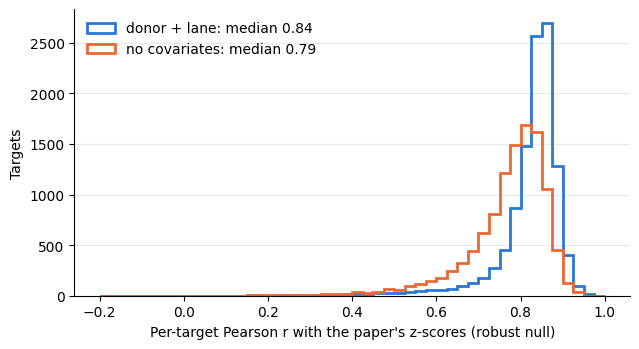

In [9]:
ADJUSTED, UNADJUSTED = '#2a78d6', '#eb6834'
fig, ax = plt.subplots(figsize=(6.5, 3.6))
bins = np.linspace(-0.2, 1.0, 49)
for name, color in (('donor + lane', ADJUSTED), ('no covariates', UNADJUSTED)):
    r = per_target[name, 'robust']
    ax.hist(r[np.isfinite(r)], bins=bins, histtype='step', linewidth=2, color=color,
            label=f'{name}: median {np.nanmedian(r):.2f}')
ax.set_xlabel("Per-target Pearson r with the paper's z-scores (robust null)")
ax.set_ylabel('Targets')
ax.legend(frameon=False, loc='upper left')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.grid(axis='y', color='#e8e8e6', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()

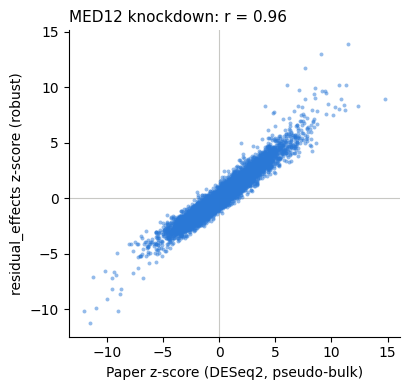

In [10]:
main_z = on(main['targets'], main['genes'], main['z_robust'], targets, genes)
r_main = per_target['donor + lane', 'robust']
example = targets[np.argmax(np.where(strong, np.nan_to_num(r_main, nan=-1), -np.inf))]
i = targets.get_loc(example)
fig, ax = plt.subplots(figsize=(4.2, 4.0))
ax.scatter(paper_z[i], main_z[i], s=8, color=ADJUSTED, alpha=0.5, linewidths=0)
ax.axhline(0, color='#c8c8c4', linewidth=0.8, zorder=0)
ax.axvline(0, color='#c8c8c4', linewidth=0.8, zorder=0)
ax.set_xlabel('Paper z-score (DESeq2, pseudo-bulk)')
ax.set_ylabel('residual_effects z-score (robust)')
ax.set_title(f'{example} knockdown: r = {r_main[i]:.2f}', loc='left', fontsize=11)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout()

A knockdown should lower its own target gene. Among targets whose own gene is tested:

In [11]:
own = main['genes'].get_indexer(main['targets'])
measured_own = (own >= 0) & main['var']['tested'].to_numpy()[np.maximum(own, 0)]
own_effect = main['effect'][np.flatnonzero(measured_own), own[measured_own]]
print(f'{measured_own.sum():,} targets: own-gene effect negative for {np.mean(own_effect < 0):.1%}, '
      f'median {np.median(own_effect):.2f} (log1p CP10k)')

7,257 targets: own-gene effect negative for 97.7%, median -0.25 (log1p CP10k)


# Part 2 — Validation on held-out donors

Agreement with the paper shows how close the two methods are, not which one is right. To compare them
fairly, both are fitted on the **same two donors, D1 and D2**: `residual_effects` (donor + lane, robust
null) on our file, and the authors' DESeq2 fit for that pair, published in
`GWCD4i.DE_stats.by_donors.h5mu`. Both are then checked against **D3 and D4**, the two donors of the
other 10x run, which neither fit has seen.

There is no method-free truth, so each fit is checked against three estimates from the held-out donors,
each biased in its own way:

- **residual_effects** (donor + lane): our method, so it may favour `residual_effects`;
- **no covariates** (target mean minus control mean): the least modelled;
- **paper DESeq2** (the authors' fit on D3 + D4): their pipeline, so it may favour DESeq2.

The authors' tables name donors by ID: D1 = CE0008162, D2 = CE0010866, D3 = CE0008678, D4 = CE0006864.

In [12]:
held_out = {  # name: (donors, covariates, output file)
    'fit on D1+D2': (['D1', 'D2'], ['donor', 'lane_id'], 'heldout_fit_D1D2.h5ad'),
    'held out D3+D4, donor + lane': (['D3', 'D4'], ['donor', 'lane_id'], 'heldout_D3D4_adjusted.h5ad'),
    'held out D3+D4, no covariates': (['D3', 'D4'], [], 'heldout_D3D4_unadjusted.h5ad'),
}
validation = {}
for name, (donors, covariates, filename) in held_out.items():
    with measured(f'residual_effects, {name}'):
        validation[name] = load_effects(cx.tl.residual_effects(
            merged_path, labels.where(obs['donor'].isin(donors)), 'non-targeting',
            covariates=covariates, null='robust', gene_name_column='gene_name', min_cells=5,
            output_path=OUTPUT_DIR / filename, verbose=0,
        ))

pairs = DATA_DIR / 'GWCD4i.DE_stats.by_donors.h5mu'
paper_d12 = paper_table(pairs, 'CE0008162_CE0010866')  # D1 + D2
paper_d34 = paper_table(pairs, 'CE0006864_CE0008678')  # D4 + D3

ours_d12 = validation['fit on D1+D2']
held_adjusted = validation['held out D3+D4, donor + lane']
held_plain = validation['held out D3+D4, no covariates']
T = ours_d12['targets']
for table in (paper_d12, paper_d34, held_adjusted, held_plain):
    T = T.intersection(table['targets'])
G = ours_d12['genes'][ours_d12['var']['tested'].to_numpy()].intersection(paper_d12['genes'])
G = G.intersection(paper_d34['genes'])
fits = {
    'residual_effects': (on(ours_d12['targets'], ours_d12['genes'], ours_d12['z_robust'], T, G),
                         on(ours_d12['targets'], ours_d12['genes'], ours_d12['padj'], T, G)),
    'paper DESeq2': (on(paper_d12['targets'], paper_d12['genes'], paper_d12['zscore'], T, G),
                     on(paper_d12['targets'], paper_d12['genes'], paper_d12['adj_p_value'], T, G)),
}
truths = {  # three estimates on the held-out donors, each made a different way
    'residual_effects': on(held_adjusted['targets'], held_adjusted['genes'], held_adjusted['z_robust'], T, G),
    'no covariates': on(held_plain['targets'], held_plain['genes'], held_plain['z_robust'], T, G),
    'paper DESeq2': on(paper_d34['targets'], paper_d34['genes'], paper_d34['zscore'], T, G),
}
print(f'{len(T):,} targets and {len(G):,} genes in every table '
      '(the per-pair tables keep only targets testable within the pair)')

residual_effects, fit on D1+D2: 0.9 min, peak RSS 60.4 GB
residual_effects, held out D3+D4, donor + lane: 0.9 min, peak RSS 68.4 GB
residual_effects, held out D3+D4, no covariates: 0.9 min, peak RSS 75.5 GB
1,553 targets and 7,354 genes in every table (the per-pair tables keep only targets testable within the pair)


## Do the calls replicate?

The first table gives, for each set of calls, the share whose direction the held-out estimate shares.
`residual_effects` calls about twice as many hits as DESeq2, so it is also compared at **equal size**:
for each target, its top *k* genes by |z|, where *k* is the number of hits DESeq2 calls for that target.
The second table gives each fit's median per-target correlation with each held-out estimate.

In [13]:
def top_k(z, k):
    # each target's k genes with the largest |z|
    score = np.where(np.isfinite(z), np.abs(z), -1)
    order = np.argsort(-score, axis=1)
    calls = np.zeros(z.shape, dtype=bool)
    for i in range(len(z)):
        calls[i, order[i, :k[i]]] = True
    return calls & (score >= 0)


ours_z, ours_q = fits['residual_effects']
paper_fit_z, paper_fit_q = fits['paper DESeq2']
paper_calls = (paper_fit_q < 0.1) & np.isfinite(paper_fit_z)
call_sets = {  # (fit, calls): (z of that fit, which genes it calls)
    ('residual_effects', 'all hits'): (ours_z, (ours_q < 0.1) & np.isfinite(ours_z)),
    ('residual_effects', 'top k per target'): (ours_z, top_k(ours_z, paper_calls.sum(axis=1))),
    ('paper DESeq2', 'all hits'): (paper_fit_z, paper_calls),
}
same_sign = pd.DataFrame({
    (fit, calls, int(called.sum())): {
        held: np.mean(np.sign(z[called & np.isfinite(truth)]) == np.sign(truth[called & np.isfinite(truth)]))
        for held, truth in truths.items()
    }
    for (fit, calls), (z, called) in call_sets.items()
}).T.rename_axis(['fit', 'calls', 'n'])
median_r = pd.DataFrame({
    fit: {held: np.nanmedian(per_target_r(z, truth)) for held, truth in truths.items()}
    for fit, (z, _) in fits.items()
}).T.rename_axis('fit')
display(same_sign.round(3))
median_r.round(3)

residual_effects  no covariates  \
fit              calls            n                                         
residual_effects all hits         501401             0.646          0.645   
                 top k per target 236383             0.745          0.741   
paper DESeq2     all hits         236383             0.747          0.743   

                                          paper DESeq2  
fit              calls            n                     
residual_effects all hits         501401         0.641  
                 top k per target 236383         0.731  
paper DESeq2     all hits         236383         0.778

,residual_effects,no covariates,paper DESeq2
fit,,,
residual_effects,0.162,0.161,0.158
paper DESeq2,0.166,0.165,0.181


## Where the fits disagree, which side do the held-out donors take?

Each value is the share of pairs where the held-out estimate has the same sign as the fit named in the
row: `residual_effects` in the first three rows, the paper in the last. Only pairs where the held-out
estimate itself is clear (|z| > 2) are counted.

In [14]:
ours_z, ours_q = fits['residual_effects']
paper_fit_z, paper_fit_q = fits['paper DESeq2']
both = np.isfinite(ours_z) & np.isfinite(paper_fit_z)
ours_hit, paper_hit = (ours_q < 0.1) & both, (paper_fit_q < 0.1) & both
cases = {  # case: (pairs, which fit's sign to check against)
    'significant in both, opposite signs': (ours_hit & paper_hit & (np.sign(ours_z) != np.sign(paper_fit_z)), ours_z),
    'paper hit, residual_effects opposite': (paper_hit & (np.sign(ours_z) != np.sign(paper_fit_z)), ours_z),
    'significant in residual_effects only': (ours_hit & ~paper_hit, ours_z),
    'significant in the paper only': (paper_hit & ~ours_hit, paper_fit_z),
}
rows = []
for case, (mask, z) in cases.items():
    row = {'case': case, 'pairs': int(mask.sum())}
    for held, truth in truths.items():
        clear = mask & np.isfinite(truth) & (np.abs(truth) > 2)
        row[held] = np.mean(np.sign(truth[clear]) == np.sign(z[clear]))
    rows.append(row)
pd.DataFrame(rows).set_index(['case', 'pairs']).round(2)

,,residual_effects,no covariates,paper DESeq2
case,pairs,,,
"significant in both, opposite signs",149,0.31,0.20,0.06
"paper hit, residual_effects opposite",3136,0.31,0.29,0.06
significant in residual_effects only,377876,0.82,0.81,0.78
significant in the paper only,112858,0.92,0.92,0.95


## Why the two disagree

Back to the full data of part 1: the authors' hits that `residual_effects` (donor + lane) gives the
opposite sign, and the targets with the most of them.

In [15]:
opposite = hits & np.isfinite(main_z) & (np.sign(main_z) != np.sign(paper_z))
print(f'{opposite.sum():,} of {hits.sum():,} paper hits ({opposite.sum() / hits.sum():.1%}) have the opposite '
      f'sign in residual_effects; their median |z| there is {np.median(np.abs(main_z[opposite])):.2f}, '
      f'and {(opposite & (np.abs(main_z) > 3)).sum():,} reach |z| > 3')
per_target_opposite = pd.Series(opposite.sum(axis=1), index=targets)
top = per_target_opposite.sort_values(ascending=False).head(10).index
print(f'the 10 targets with the most hold {per_target_opposite[top].sum() / opposite.sum():.0%} of them')
table = paper_meta.loc[top].assign(
    opposite_sign=per_target_opposite[top],
    cells_here=pd.Series(main['n_cells'], index=main['targets'])[top],
)
table[['opposite_sign', 'n_total_de_genes', 'cells_here', 'ontarget_significant',
       'donor_correlation_all_mean']].rename(columns={
    'opposite_sign': 'opposite-sign hits', 'n_total_de_genes': 'paper hits', 'cells_here': 'cells',
    'ontarget_significant': 'knockdown significant', 'donor_correlation_all_mean': 'donor agreement (r)',
}).round(2)

2,888 of 513,877 paper hits (0.6%) have the opposite sign in residual_effects; their median |z| there is 0.36, and 64 reach |z| > 3
the 10 targets with the most hold 23% of them


,opposite-sign hits,paper hits,cells,knockdown significant,donor agreement (r)
ZMYM2,174,2178,580,True,0.11
ATP2A2,69,3519,268,True,0.51
TRAF3,68,1344,6962,True,0.48
CCNC,66,2731,3530,True,0.24
SMG1,66,2034,484,True,0.17
SMAD7,60,335,1322,True,0.04
C11orf54,53,1045,710,True,0.07
UBXN1,43,4440,592,True,0.09
SETDB1,38,2291,4563,True,0.58
NFAT5,37,1624,394,True,0.35


These flips are rare and weak: `residual_effects` gives most of them a z-score near zero. They are
spread over many targets. The targets with the most of them are not weak knockdowns (all ten knock down
their own gene), but for half of them the authors' own measure of agreement between donors is below
0.2, so their effects are not consistent across donors in either analysis.

The covariates matter more. Depth and mitochondrial share change with many knockdowns, so adjusting for
them removes part of the effect. Compare the share of opposite-sign hits under the two adjusted designs,
and how it grows with the change in depth a knockdown causes:

In [16]:
full_z = on(effects['donor + lane + depth + mito']['targets'], effects['donor + lane + depth + mito']['genes'],
            effects['donor + lane + depth + mito']['z_robust'], targets, genes)
opposite_full = hits & np.isfinite(full_z) & (np.sign(full_z) != np.sign(paper_z))
print(f"paper hits with the opposite sign: donor + lane {opposite.sum() / hits.sum():.2%}, "
      f"donor + lane + depth + mito {opposite_full.sum() / hits.sum():.2%}. Of the latter, donor + lane "
      f"gives the paper's sign for {np.mean(np.sign(main_z[opposite_full]) == np.sign(paper_z[opposite_full])):.0%}.")

log_total = np.log(obs['total_counts'].astype(float))
control = labels.eq('non-targeting')
depth_shift = (log_total.groupby(labels).mean() - log_total[control].mean()).reindex(targets).abs()
share = pd.DataFrame({
    'depth shift': depth_shift.to_numpy(),
    'donor + lane': opposite.sum(axis=1) / np.maximum(hits.sum(axis=1), 1),
    'donor + lane + depth + mito': opposite_full.sum(axis=1) / np.maximum(hits.sum(axis=1), 1),
    'hits': hits.sum(axis=1),
}, index=targets).query('hits >= 20')
share.groupby(pd.qcut(share['depth shift'], 4, labels=['smallest', '2nd', '3rd', 'largest'])
              .rename('depth shift (quartile)'), observed=True)[
    ['donor + lane', 'donor + lane + depth + mito']].mean().round(3)

paper hits with the opposite sign: donor + lane 0.56%, donor + lane + depth + mito 1.91%. Of the latter, donor + lane gives the paper's sign for 76%.


,donor + lane,donor + lane + depth + mito
depth shift (quartile),,
smallest,0.009,0.012
2nd,0.009,0.015
3rd,0.005,0.012
largest,0.005,0.023


## Resources

Wall time and peak memory of this notebook's process for each step. The peak includes the
targets × genes matrices the notebook keeps for its comparisons, which is why it grows in part 2. The
`residual_effects` runs read a file written moments before, much of it still cached in memory.

In [17]:
resources = pd.DataFrame(steps).set_index('step')
resources.loc['total'] = [resources['wall time (min)'].sum(), resources['peak RSS (GB)'].max()]
resources

,wall time (min),peak RSS (GB)
step,,
keep guide-resolved cells (4 files),11.2,6.9
concatenate the donors,6.8,8.9
"residual_effects, donor + lane",1.6,18.5
"residual_effects, donor + lane + depth + mito",1.2,17.3
"residual_effects, no covariates",1.2,16.1
"residual_effects, fit on D1+D2",0.9,60.4
"residual_effects, held out D3+D4, donor + lane",0.9,68.4
"residual_effects, held out D3+D4, no covariates",0.9,75.5
total,24.7,75.5


## Takeaways

- **Use `covariates=['donor', 'lane_id']`** (or whatever describes how cells were processed) **and
  `null='robust'`** on genome-wide screens. On this screen it agrees best with the authors' analysis
  (median r 0.84; 99.4% of their hits with the same sign; 1.0% of their non-hits with |z| > 3).
- **Keep `null='model'` for focused panels**, where most targets are active. Here it calls a strong
  effect for 4.4% of the authors' non-hits.
- **Don't adjust for depth or mitochondrial share** unless the effect at equal depth is the question.
  It raises the opposite-sign share of the authors' hits from 0.6% to 1.9%, mostly for knockdowns that
  change depth the most.
- **Neither method is clearly better on held-out donors.** At an equal number of calls, the two
  replicate about equally often (about 74% same sign), except against the authors' own D3 + D4 fit, which
  favours DESeq2. `residual_effects` calls twice as many hits, and about 80% of its extra calls
  replicate. The few direct contradictions mostly go the paper's way.